# 04. Финальная модель (v2): оценка на тестовой выборке, гипотеза H3, выгрузка

**Блок 3.3.** По итогам блока 3.2 финальный алгоритм — логистическая регрессия (наибольшее PR-AUC на
кросс-валидации). Версия **v2** отличается от baseline **v1** правилом выбора порога:

| | v1 (baseline) | v2 (финальная) |
|---|---|---|
| Порог | наибольший, при котором Recall на кросс-валидации ≥ 0,85 | наибольший, при котором **нижняя граница 95% ДИ** Recall (бутстрап по двигателям) ≥ 0,85 |

Тестовая выборка (100 двигателей, наблюдения обрываются до отказа) в этом ноутбуке используется впервые.
Ничего по результатам теста не подбирается.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix

from src.models.data import load_features, split_xy
from src.models.metrics import (FN_COST, FP_COST, MAX_FPR, MIN_RECALL, bootstrap_ci, engine_alerts,
                                error_cost, evaluate, false_positive_rate)
from src.models.predict import FailurePredictor
from src.models.registry import load_model
from src.models.train_final import run

FIG_DIR = ROOT / "docs" / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
train, test = load_features()

## 1. Обучение v2 и сохранение

`run` подбирает порог на кросс-валидации train, обучает модель на всём train, оценивает на test и сохраняет `models/final_v2.joblib` и `models/final_v2.json`.

In [2]:
res = run(train, test, save=True)
thr2 = res["threshold"]
print(f"Порог v2 = {thr2:.4f}; нижняя граница 95% ДИ Recall на кросс-валидации = {res['threshold_info']['recall_ci_lower']:.3f}")

Порог v2 = 0.9721; нижняя граница 95% ДИ Recall на кросс-валидации = 0.850


## 2. Тестовая выборка: v1 и v2

In [3]:
v1, meta1 = load_model("baseline_v1")
X_test, y_test, g_test = split_xy(test, meta1["features"])
p1 = v1.predict_proba(X_test)[:, 1]
p2 = res["_test_proba"]
thr1 = meta1["threshold"]
assert np.allclose(p1, p2), "у v1 и v2 одна и та же модель; различается только порог"

def row(name, p, thr):
    m = evaluate(y_test, p, thr)
    e = engine_alerts(g_test, test["rul"], p, thr)
    pred = (p >= thr).astype(int)
    return {"версия": name, "порог": thr, "Recall": m["recall"], "FPR": m["fpr"], "Precision": m["precision"],
            "F2": m["f2"], "PR-AUC": m["pr_auc"], "пропусков (FN)": int(((y_test == 1) & (pred == 0)).sum()),
            "ложных тревог (FP)": int(((y_test == 0) & (pred == 1)).sum()),
            "двигателей с тревогой": f"{round(e['detected_share'] * e['engines'])} из {e['engines']}",
            "медиана запаса, циклов": e["median_lead"]}

versions = pd.DataFrame([row("v1 (baseline)", p1, thr1), row("v2 (финальная)", p2, thr2)]).set_index("версия")
versions

,порог,Recall,FPR,Precision,F2,PR-AUC,пропусков (FN),ложных тревог (FP),двигателей с тревогой,"медиана запаса, циклов"
версия,,,,,,,,,,
v1 (baseline),0.9842,0.6777,0.0004,0.9783,0.7221,0.9401,107,5,19 из 25,27.0
v2 (финальная),0.9721,0.7139,0.0010,0.9480,0.7510,0.9401,95,13,21 из 25,26.0


Обученная модель в v1 и v2 одна и та же (одинаковые алгоритм, гиперпараметры, данные), поэтому PR-AUC совпадает; различаются только порог и, как следствие, метрики при пороге.

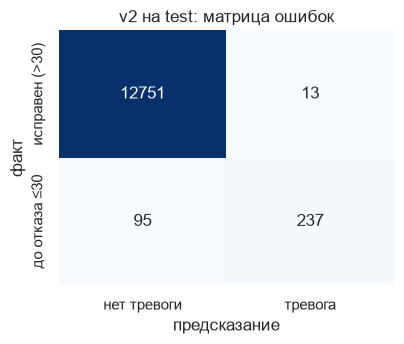

In [4]:
cm = confusion_matrix(y_test, (p2 >= thr2).astype(int))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["нет тревоги", "тревога"], yticklabels=["исправен (>30)", "до отказа ≤30"])
ax.set(xlabel="предсказание", ylabel="факт", title="v2 на test: матрица ошибок")
plt.tight_layout(); fig.savefig(FIG_DIR / "04_confusion_matrix.png", dpi=120); plt.show()

## 3. Гипотеза H3

*Финальная модель с подобранным порогом выполняет бизнес-требования на отложенных двигателях.*
Бутстрап по тестовым двигателям (1000 повторов), 95% доверительные интервалы.
Критерий: нижняя граница Recall ≥ 0,85 **и** верхняя граница FPR < 0,15.

In [5]:
h3 = res["h3"]
pd.DataFrame({
    "точечная оценка": [h3["recall"]["point"], h3["fpr"]["point"]],
    "95% ДИ: нижняя": [h3["recall"]["lo"], h3["fpr"]["lo"]],
    "95% ДИ: верхняя": [h3["recall"]["hi"], h3["fpr"]["hi"]],
    "требование": ["нижняя ≥ 0,85", "верхняя < 0,15"],
    "выполнено": [h3["recall"]["lo"] >= MIN_RECALL, h3["fpr"]["hi"] < MAX_FPR],
}, index=["Recall", "FPR"])

,точечная оценка,95% ДИ: нижняя,95% ДИ: верхняя,требование,выполнено
Recall,0.7139,0.5912,0.8033,"нижняя ≥ 0,85",False
FPR,0.0010,0.0005,0.0017,"верхняя < 0,15",True


In [6]:
print("H3 подтверждена:", h3["confirmed"])
print(f"Двигателей в бутстрапе: {h3['engines']}, из них с положительными строками: {h3['engines_with_positives']}")

H3 подтверждена: False
Двигателей в бутстрапе: 100, из них с положительными строками: 25


## 4. Где модель ошибается

Recall по диапазонам RUL на test (v2) и пример хода вероятности для нескольких тестовых двигателей.

In [7]:
pos = test.assign(p=p2)[test["target"] == 1]
bins = pd.cut(pos["rul"], [-1, 10, 20, 30], labels=["0–10", "11–20", "21–30"])
g = (pos["p"] >= thr2).groupby(bins, observed=True)
pd.DataFrame({"строк": g.size(), "доля строк": g.size() / len(pos), "Recall": g.mean()})

,строк,доля строк,Recall
rul,,,
0–10,17,0.0512,1.0000
11–20,106,0.3193,0.9811
21–30,209,0.6295,0.5550


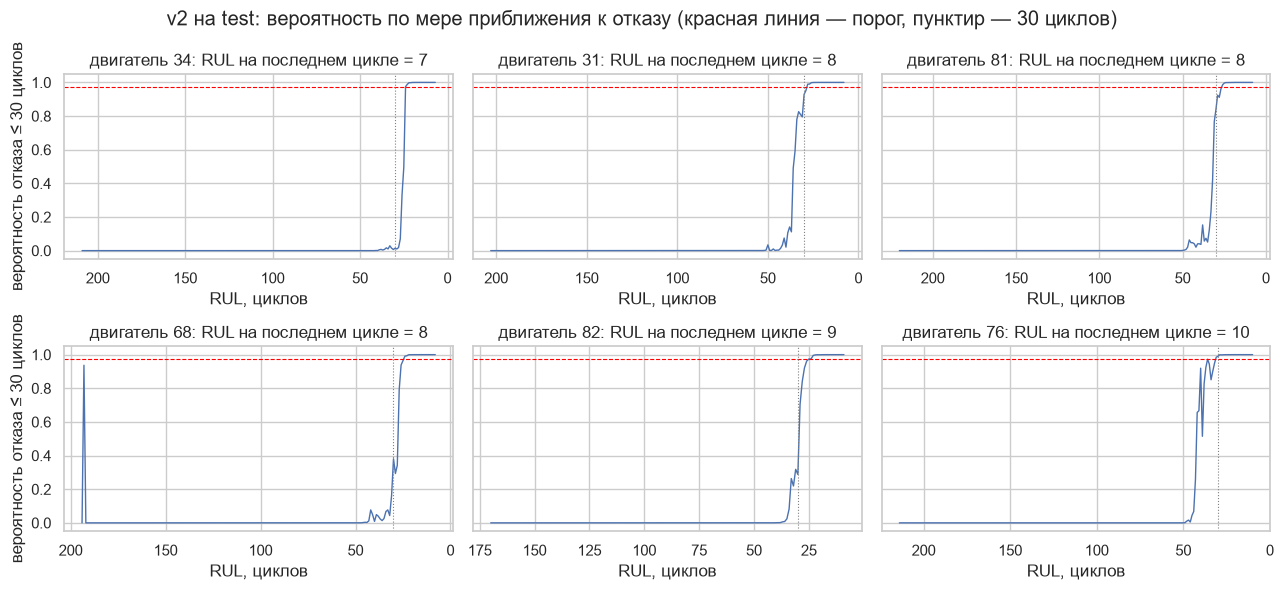

In [8]:
t = test.assign(p=p2)
last = t[t["is_last_cycle"]].sort_values("rul")
show = last[last["rul"] <= 30]["unit_id"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for ax, u in zip(axes.ravel(), show):
    d = t[t["unit_id"] == u]
    ax.plot(d["rul"], d["p"], lw=1)
    ax.axhline(thr2, color="red", ls="--", lw=0.8)
    ax.axvline(30, color="grey", ls=":", lw=0.8)
    ax.set(title=f"двигатель {u}: RUL на последнем цикле = {int(d['rul'].min())}", xlabel="RUL, циклов")
    ax.invert_xaxis()   # ось X у каждого графика своя: время идёт слева направо к отказу
axes[0, 0].set_ylabel("вероятность отказа ≤ 30 циклов"); axes[1, 0].set_ylabel("вероятность отказа ≤ 30 циклов")
fig.suptitle("v2 на test: вероятность по мере приближения к отказу (красная линия — порог, пунктир — 30 циклов)")
plt.tight_layout(); fig.savefig(FIG_DIR / "04_test_engines.png", dpi=120); plt.show()

## 5. Сравнение с обслуживанием по регламенту

Регламент: тревога, когда двигатель отработал заданное число циклов (возраст), независимо от показаний датчиков.
Пороговый возраст выбирается **на train** тем же способом — наибольший возраст, при котором Recall ≥ 0,85.
Стоимость ошибок — по экспертному соотношению из блока 1: пропуск = 10, ложная тревога = 1 (условные единицы).

In [9]:
age_ok = [a for a in range(1, int(train["cycle"].max()) + 1)
          if ((train["cycle"] >= a) & (train["target"] == 1)).sum() / (train["target"] == 1).sum() >= MIN_RECALL]
age_threshold = max(age_ok)
print("Регламент: тревога с цикла", age_threshold)

policies = {
    f"Регламент (возраст ≥ {age_threshold})": (test["cycle"] >= age_threshold).astype(int),
    "Модель v1": (p1 >= thr1).astype(int),
    "Модель v2": (p2 >= thr2).astype(int),
}
rows = []
for name, pred in policies.items():
    tp = int(((y_test == 1) & (pred == 1)).sum())
    rows.append({"стратегия": name, "Recall": tp / int(y_test.sum()), "FPR": false_positive_rate(y_test, pred),
                 "пропусков": int(((y_test == 1) & (pred == 0)).sum()), "ложных тревог": int(((y_test == 0) & (pred == 1)).sum()),
                 f"стоимость ошибок ({FN_COST}:{FP_COST})": error_cost(y_test, pred)})
policy_cmp = pd.DataFrame(rows).set_index("стратегия")
policy_cmp

Регламент: тревога с цикла 146


,Recall,FPR,пропусков,ложных тревог,стоимость ошибок (10:1)
стратегия,,,,,
Регламент (возраст ≥ 146),0.7139,0.0971,95,1240,2190.0
Модель v1,0.6777,0.0004,107,5,1075.0
Модель v2,0.7139,0.0010,95,13,963.0


## 6. Справочно: компромисс Recall/FPR на test

**Не используется для выбора порога** (иначе оценка станет нечестной) — только чтобы понять, насколько далеко
требование. Показано, каким был бы Recall и FPR на test при других порогах.

In [10]:
grid = [0.5, 0.7, 0.8, 0.9, 0.95, thr2]
pd.DataFrame([{"порог": g, "Recall": ((p2 >= g) & (y_test == 1)).sum() / y_test.sum(),
               "FPR": false_positive_rate(y_test, (p2 >= g).astype(int))} for g in grid]).set_index("порог")

,Recall,FPR
порог,,
0.5000,0.9127,0.0063
0.7000,0.8886,0.0043
0.8000,0.8584,0.0037
0.9000,0.8223,0.0030
0.9500,0.7711,0.0018
0.9721,0.7139,0.0010


## 7. Время ответа и сохранённые артефакты

In [11]:
print("Задержка одной строки:", {k: round(v, 2) for k, v in res["latency_single_row"].items()})
meta = json.loads((ROOT / "models" / "final_v2.json").read_text(encoding="utf-8"))
print("Файлы:", [p.name for p in sorted((ROOT / "models").glob("final_v2.*"))])
print("Версии библиотек:", meta["libraries"])
print("Отпечаток данных (MD5):", meta["data"]["md5"])

Задержка одной строки: {'p50_ms': 1.61, 'p95_ms': 1.91, 'n': 1000}
Файлы: ['final_v2.joblib', 'final_v2.json']
Версии библиотек: {'python': '3.12.10', 'scikit-learn': '1.9.1', 'pandas': '3.1.1', 'numpy': '2.5.5', 'scipy': '1.18.1', 'joblib': '1.6.0'}
Отпечаток данных (MD5): {'train_FD001.txt': '259f340bac32ce6fa8894815600fa757', 'test_FD001.txt': '62316d1dd70f88a9a43a1e2690765437', 'RUL_FD001.txt': '8f4a8b3d2692b2f7d8e72b344927bf4b'}


In [12]:
# Проверка загрузки из файла: так модель будет использоваться в API
predictor = FailurePredictor("final_v2")
sample = test[test["is_last_cycle"]].sort_values("rul").head(3)
pd.concat([sample[["unit_id", "cycle", "rul"]].reset_index(drop=True),
           predictor.predict(sample).reset_index(drop=True)], axis=1)

,unit_id,cycle,rul,probability,alarm
0,34,203,7,1.0,True
1,31,196,8,1.0,True
2,81,213,8,1.0,True


## 8. Выводы

**Итог на тестовой выборке (v2, порог 0,972):**

| Требование | Результат на test | Выполнено |
|---|---|---|
| Recall ≥ 0,85 | 0,714 (95% ДИ 0,59–0,80) | **нет** |
| FPR < 0,15 | 0,001 (95% ДИ 0,0005–0,0017) | да |
| Время инференса < 50 мс | p95 ≈ 2 мс на одну строку (замеры колеблются в пределах 1,9–2,3 мс) (только модель; весь запрос — в блоке 5) | да (для модели) |
| Доля отказов, предупреждённых заранее, ≥ 85% | 21 из 25 двигателей = 84% | почти (не хватает одного двигателя) |
| Медиана запаса времени ≥ 15 циклов | 26 циклов | да |

- **H3 не подтверждена:** нижняя граница Recall (0,59) ниже 0,85; по FPR критерий выполнен с большим запасом.
- **v2 лучше v1** на тех же данных: Recall 0,714 против 0,678, пропусков 95 против 107, предупреждено 21 двигатель
  вместо 19; цена — 13 ложных тревог вместо 5 из 12 764 исправных состояний.
- **Причина невыполнения Recall** та же, что в блоке 3.1: 63% положительных строк test приходятся на диапазон
  RUL 21–30, где Recall 0,56; в диапазонах 0–10 и 11–20 Recall 1,00 и 0,98. Наблюдения тестовых двигателей
  обрываются до отказа, поэтому «трудных» строк в test вдвое больше, чем в train.
- **Модель выгоднее регламента.** Регламентная замена по возрасту (тревога с 146-го цикла, выбрано на train)
  даёт на test тот же Recall 0,714, но в 95 раз больше ложных тревог (1 240 против 13). Условная стоимость ошибок
  (пропуск : ложная тревога = 10 : 1): 2 190 у регламента против 963 у v2 — **на 56% меньше**.
- **Требование достижимо снижением порога:** справочно, на test при пороге 0,8 Recall был бы 0,86 при FPR 0,004.
  Но выбрать порог по тесту — значит подогнать результат, поэтому в отчёте фиксируется честное невыполнение.
  Порог, откалиброванный на train, оказался слишком строгим для данных с другим составом. Рекомендация для
  эксплуатации: уточнять порог на реальных данных в теневом режиме (этап 1 A/B-теста из блока 1.3).
- **Холодный старт:** часть ложных тревог (4 из 13 на test, 5 из 34 на кросс-валидации) приходится на циклы 2–5,
  когда тренд по 2–5 точкам неустойчив. В API стоит помечать предсказания с короткой историей.
- **Выгрузка:** модель — `models/final_v2.joblib`, метаданные — `models/final_v2.json` (порог, 71 признак, метрики,
  версии Python 3.12.10, scikit-learn 1.9.1, pandas 3.1.1, numpy 2.5.5, scipy 1.18.1, joblib 1.6.0, MD5 исходных
  файлов). Полный список зависимостей с версиями — `requirements.txt`. Загрузка для API — `src/models/predict.py`.